# Yield curve factor analysis demo

Load US Treasury par yield curve rates (with cached and synthetic fallbacks), then decompose the panel with PCA and NMF. PCA recovers the classic level, slope, and curvature factors of the term structure.

In [1]:
import pandas as pd

from yieldcurve import compare_reconstruction, fit_nmf, fit_pca, load_yield_curve

panel, source = load_yield_curve()
panel.tail(3)

Data source: live US Treasury download (880 days), cached to data\treasury_yields.csv


,1 Mo,2 Mo,3 Mo,6 Mo,1 Yr,2 Yr,3 Yr,5 Yr,7 Yr,10 Yr,20 Yr,30 Yr
Date,,,,,,,,,,,,
2026-07-08,3.67,3.82,3.87,3.99,4.06,4.21,4.21,4.31,4.43,4.56,5.07,5.06
2026-07-09,3.72,3.79,3.83,3.96,4.02,4.16,4.18,4.27,4.40,4.54,5.06,5.05
2026-07-10,3.71,3.81,3.85,3.99,4.06,4.21,4.22,4.30,4.42,4.56,5.08,5.06


## PCA: level, slope, curvature

PCA on the mean-centered panel. The first component loads almost uniformly across maturities (level), the second changes sign between short and long tenors (slope), and the third is hump-shaped (curvature).

Explained variance ratio: [0.7741 0.1738 0.0406]
Cumulative: 0.9884


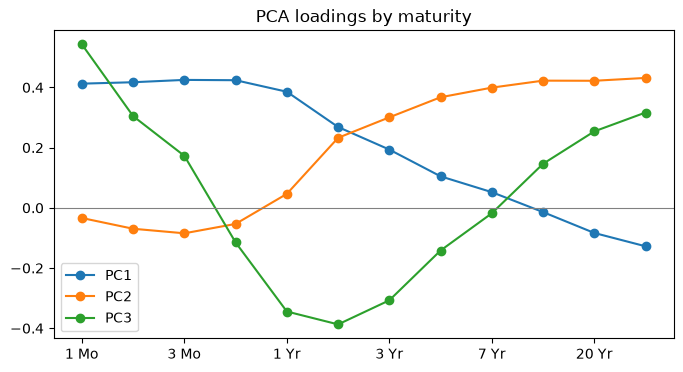

In [2]:
pca = fit_pca(panel, n_components=3)
print("Explained variance ratio:", pca.explained_variance_ratio.round(4))
print("Cumulative:", pca.explained_variance_ratio.sum().round(4))
ax = pca.loadings.plot(marker="o", figsize=(8, 4), title="PCA loadings by maturity")
ax.axhline(0, color="gray", lw=0.8);

## NMF and reconstruction comparison

NMF factorizes the raw nonnegative panel into nonnegative basis curves. PCA, which also fits the mean, reconstructs more accurately at matched component counts.

In [3]:
nmf = fit_nmf(panel, n_components=3)
print(f"PCA RMSE (3 components): {pca.rmse:.4f} yield points")
print(f"NMF RMSE (3 components): {nmf.rmse:.4f} yield points")
comparison = compare_reconstruction(panel)
comparison.round(4)

PCA RMSE (3 components): 0.0556 yield points
NMF RMSE (3 components): 0.0681 yield points


,pca_rmse,nmf_rmse
n_components,,
1,0.2459,0.3703
2,0.1181,0.1297
3,0.0556,0.0681
4,0.0365,0.0531
5,0.0208,0.0586


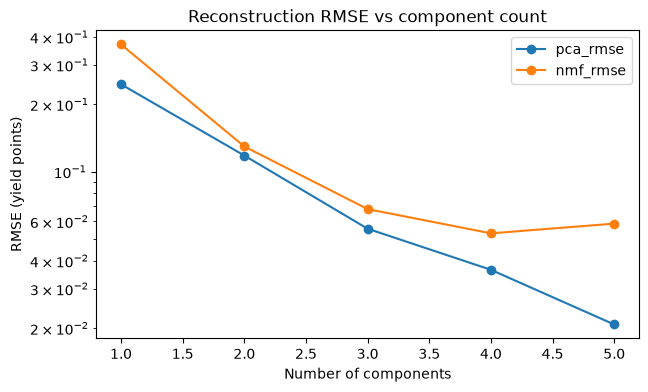

In [4]:
ax = comparison.plot(marker="o", logy=True, figsize=(7, 4), title="Reconstruction RMSE vs component count")
ax.set_xlabel("Number of components")
ax.set_ylabel("RMSE (yield points)");

## Factor scores over time

The PC1 score tracks the overall rate level, PC2 the steepness of the curve.

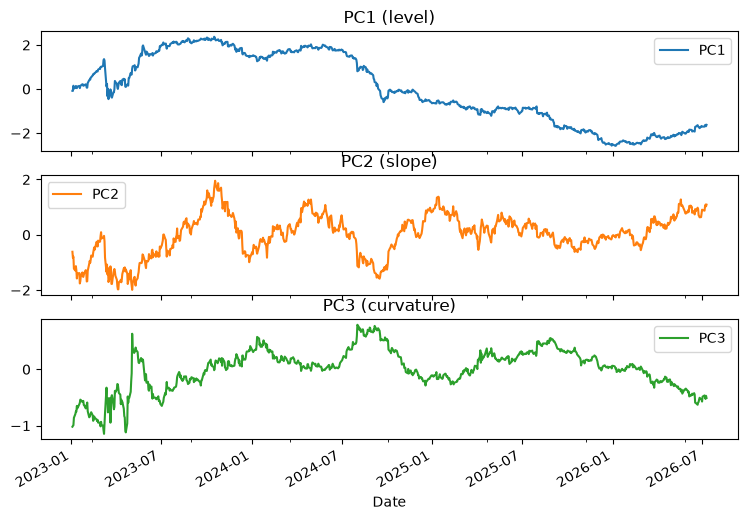

In [5]:
pca.scores.plot(subplots=True, figsize=(9, 6), title=["PC1 (level)", "PC2 (slope)", "PC3 (curvature)"]);

Data source used in this run is printed by the first cell (`treasury`, `cache`, or `synthetic`).